# MLflow, from experiment to production: the Telco churn lab

Companion notebook of the **Data Science team training** deck. One project from start to finish: a churn classifier for *Telco*, a fictional telecom operator, built on the public IBM Telco churn sample (7,043 customers, 19 features), then a GenAI assistant on top of it.

### Where the code runs, where MLflow lives
On real projects the code often runs **outside** the platform that stores the results: a laptop, a VM, a CI job, a notebook service. This lab reproduces that: the notebook runs in **Google Colab**, and everything it produces (runs, models, prompts, traces, data tables) goes to a **remote Databricks workspace** through its APIs.

| Option | How | When |
|---|---|---|
| **A. Colab + remote Databricks** *(this training)* | Colab runs the code; a personal access token connects it to Databricks | Code runs anywhere: laptop, VM, CI, Colab |
| B. Databricks Git folder | *Workspace > Create > Git folder* with the repo URL, then run it on *Serverless* | The team works inside Databricks |
| C. Databricks import | Create a folder in *Home*, *Import* the notebook, create `data/` and import the CSV | No Git access in the workspace |

The same MLflow code works in all three; only the connection cell changes. Inside Databricks (B, C) you are already authenticated, so step 1.3 can be skipped.

### What you need (option A)
* A **Databricks workspace**: Free Edition is enough (free, at databricks.com/learn/free-edition).
* A **Google account** for Colab.
* Two connection items from the workspace, explained in step 1.1: the **workspace URL** and a **personal access token**.

### How the training uses this notebook
The deck and this notebook follow the same seven modules. After the slides of a module, the trainer comes here:

* a **▶️ DEMO · Module N** banner marks where to start,
* a **⏸️ BACK TO SLIDES** banner marks where to stop and go back to the deck.

| Module | Deck chapter | What runs here |
|---|---|---|
| 1 | Setup | Connection items, install, remote connection check, folders and schema |
| 2 | Core concepts | Data into a Delta table, first run by hand, autolog |
| 3 | Tracking | Grid search as nested runs, baseline, `search_runs` |
| 4 | Versioning | Delta table versions (time travel), dataset digests, lineage |
| 5 | Registry and deployment | Signature, Unity Catalog registry, aliases, batch call list |
| 6 | Observability | Champion vs. challenger evaluation, weekly drift monitoring |
| 7 | Bonus: LLMOps | Prompt registry, tracing, GenAI evaluation, AI Gateway |

Everything the lab creates lives in the Databricks workspace: the **experiments** under `/Shared/telco/` (left bar: *Experiments*) and the **schema** `workspace.telco` in Unity Catalog (left bar: *Catalog*), which holds the data tables, the model and the prompt.

---
# ▶️ DEMO · Module 1 · Setup

*You just finished the slides of module 1 (01 Setup). Run the cells below, then show in the MLflow UI:*

1. where to find the workspace URL and how to create a personal access token
2. the Colab secrets panel (key icon) with `DATABRICKS_HOST` and `DATABRICKS_TOKEN`
3. the connection check: your Databricks user name, printed from Colab
4. in Databricks: the folder `/Shared/telco/churn` (*Workspace > Shared*) and the schema `workspace.telco` (*Catalog*)

## 1.1 Get the two connection items from Databricks

Do this once, in the Databricks workspace, in your browser.

**1. Workspace URL** (`DATABRICKS_HOST`)
* Log in to Databricks and look at the browser address bar.
* Keep only the start, up to the domain: `https://dbc-1a2b3c4d-5e6f.cloud.databricks.com`
* Drop everything after it (`/browse`, `?o=1234...`): the next cells clean it anyway.

**2. Personal access token** (`DATABRICKS_TOKEN`)
* Click your **avatar** (top right) > **Settings**.
* In the left menu: **User > Developer**.
* Next to **Access tokens**, click **Manage** > **Generate new token**.
* Comment: `colab-mlflow-lab`, lifetime: `30` days > **Generate**.
* **Copy the token now** (it starts with `dapi`): Databricks shows it only once.

A token acts as your password for the API: never paste it in a cell, a slide or a chat. If it leaks, revoke it on the same page.

**3. Store both in Colab secrets**
* In Colab, click the **key icon** 🔑 in the left bar (*Secrets*).
* **Add new secret** twice:
  * name `DATABRICKS_HOST`, value: the workspace URL;
  * name `DATABRICKS_TOKEN`, value: the token.
* Turn on **Notebook access** for both.

Secrets stay attached to your Google account, not to the notebook: sharing the notebook never shares your token.

## 1.2 Install the libraries

Colab already has pandas and matplotlib. We pin **scikit-learn** below 1.9 (version 1.9 changed the random forest slightly, and we want everyone to get the same scores as the slides), and install **MLflow** with its Databricks extras (3.17 or later for the GenAI features), the **Databricks SDK** (folders, SQL, files, endpoints) and the **OpenAI client** used in the bonus.

If Colab shows *"Restart session"* after the install, click it, then continue with the next cell (no need to rerun the install).

In [1]:
%pip install -q -U "mlflow[databricks]>=3.17" "databricks-sdk>=0.50" "scikit-learn>=1.6,<1.9" openai

## 1.3 Load the connection items

The cell reads the two secrets from Colab. If they are missing (or you run outside Colab), it asks for them; the token is typed hidden and never written in the notebook.

Both MLflow and the Databricks SDK read the same two environment variables, so this is the only place we handle credentials.

In [3]:
import os
from getpass import getpass
from urllib.parse import urlparse

def read_secret(name):
    # 1) Colab secrets (key icon), 2) environment variable, 3) None
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return os.environ.get(name)

host = read_secret("DATABRICKS_HOST") or input("DATABRICKS_HOST (workspace URL): ")
token = read_secret("DATABRICKS_TOKEN") or getpass("DATABRICKS_TOKEN (personal access token): ")

# Clean common copy-paste mistakes: spaces, quotes, a "Bearer " prefix, a path after the domain
host = host.strip().strip('"').strip("'")
u = urlparse(host if host.startswith("http") else "https://" + host)
token = token.strip().strip('"').strip("'")
token = token[len("Bearer "):].strip() if token.lower().startswith("bearer ") else token

os.environ["DATABRICKS_HOST"] = f"https://{u.netloc}"      # keep https://<workspace-domain> only
os.environ["DATABRICKS_TOKEN"] = token                     # read by MLflow and the SDK, never printed
os.environ["DATABRICKS_AUTH_TYPE"] = "pat"                 # use the token, do not guess another login method

print("Host :", os.environ["DATABRICKS_HOST"])
print("Token:", f"dapi... ({len(token)} characters)" if token.startswith("dapi")
      else "WARNING: a personal access token starts with 'dapi'. You may have copied the token ID or another secret.")

Host : https://dbc-aaa87ed9-c5b5.cloud.databricks.com
Token: dapi... (36 characters)


## 1.4 Connect MLflow to the remote workspace and check it

Three settings decide where everything lands:

| Setting | Controls | Here |
|---|---|---|
| tracking URI | runs, metrics, artifacts, traces | `databricks` (the workspace in `DATABRICKS_HOST`) |
| registry URI | registered models and prompts | `databricks-uc` (Unity Catalog) |
| experiment | the folder of runs | `/Shared/telco/churn/model-training` (step 1.6) |

The check asks Databricks who you are and makes one real MLflow call. If it prints your user name, everything below will work. A wrong URL or token fails within a minute with a message saying which one to check.

In [4]:
import json, warnings
import numpy as np                    # numeric helpers (PSI computation)
import pandas as pd                   # the model is trained on pandas DataFrames
import matplotlib.pyplot as plt       # plots logged as artifacts
import mlflow
from databricks.sdk import WorkspaceClient     # Databricks API: folders, SQL, files, endpoints
from databricks.sdk.config import Config

warnings.filterwarnings("ignore")     # keep the demo output readable

mlflow.set_tracking_uri("databricks")         # runs and traces go to the remote workspace
mlflow.set_registry_uri("databricks-uc")      # models and prompts go to its Unity Catalog

# Same host + token as MLflow, explicitly as a personal access token ("pat");
# short timeouts so a wrong URL fails fast instead of retrying for minutes
w = WorkspaceClient(config=Config(host=os.environ["DATABRICKS_HOST"], token=os.environ["DATABRICKS_TOKEN"],
                                  auth_type="pat", retry_timeout_seconds=30, http_timeout_seconds=20))
try:
    me = w.current_user.me()                  # Databricks API call
    mlflow.search_experiments(max_results=1)  # MLflow API call
except Exception as e:
    msg = str(e).split(". Config:")[0]        # keep Databricks' own message, drop the long config dump
    hint = ("The token was refused. In Databricks: avatar > Settings > User > Developer > Access tokens > "
            "Generate new token, copy the value shown once (it starts with 'dapi', it is not the token ID), "
            "update the DATABRICKS_TOKEN secret, then rerun 1.3 and 1.4."
            if any(k in msg for k in ("Credential", "Invalid access token", "401", "403", "Unauthorized"))
            else "Check DATABRICKS_HOST: it must be the workspace URL, https://<something>.cloud.databricks.com")
    raise RuntimeError(f"Cannot connect to Databricks: {msg}\n-> {hint}") from None

HOST = w.config.host.rstrip("/")              # used to print clickable links
print(f"Connected to {HOST} as {me.user_name}")
print("MLflow", mlflow.__version__)

Connected to https://dbc-aaa87ed9-c5b5.cloud.databricks.com as sed.labiad@gmail.com
MLflow 3.17.2


## 1.5 A SQL warehouse to manage the data tables

Colab has no Spark. To create and read Delta tables in the workspace, we send SQL to a **SQL warehouse** through the API. Free Edition comes with one (*Serverless Starter Warehouse*); the cell picks the first one available. The first query can take up to a minute while the warehouse starts.

The three helpers below are the only plumbing in this lab:
* `sql(query)`: runs SQL on the warehouse, returns a pandas DataFrame;
* `upload_csv(df, name)`: uploads a DataFrame as a CSV file to a Unity Catalog **volume** (a folder for files in the catalog);
* `csv_select(path, columns)`: the SQL that reads such a file, used to fill tables.

In [24]:
import io, time
from databricks.sdk.service.sql import StatementState

warehouse = next(iter(w.warehouses.list()))           # Free Edition: the Serverless Starter Warehouse
WAREHOUSE_ID = warehouse.id
print("SQL warehouse:", warehouse.name)

CASTS = {"INT": "int64", "LONG": "int64", "BIGINT": "int64", "SHORT": "int64",
         "DOUBLE": "float64", "FLOAT": "float64", "DECIMAL": "float64"}

def sql(query):
    # Run one SQL statement on the warehouse and return the result as a pandas DataFrame
    r = w.statement_execution.execute_statement(
        statement=query,
        warehouse_id=WAREHOUSE_ID,
        wait_timeout="50s"
    )

    while r.status.state in (StatementState.PENDING, StatementState.RUNNING):
        time.sleep(3)
        r = w.statement_execution.get_statement(r.statement_id)

    if r.status.state != StatementState.SUCCEEDED:
        raise RuntimeError(
            f"SQL failed: {r.status.error.message if r.status.error else r.status.state}"
        )

    if not r.manifest or not r.manifest.schema or not r.manifest.schema.columns:
        return pd.DataFrame()

    cols = r.manifest.schema.columns
    rows, chunk = list(r.result.data_array or []), r.result

    while chunk.next_chunk_index is not None:
        chunk = w.statement_execution.get_statement_result_chunk_n(
            r.statement_id,
            chunk.next_chunk_index
        )
        rows += chunk.data_array or []

    out = pd.DataFrame(rows, columns=[c.name for c in cols])

    # Cast numeric columns safely, including columns containing NULL
    for c in cols:
        t = str(
            c.type_name.value
            if hasattr(c.type_name, "value")
            else c.type_name
        ).upper()

        if t in ("BYTE", "SHORT", "INT", "INTEGER", "LONG", "BIGINT"):
            out[c.name] = pd.to_numeric(
                out[c.name], errors="coerce"
            ).astype("Int64")

        elif t in ("FLOAT", "DOUBLE", "DECIMAL"):
            out[c.name] = pd.to_numeric(
                out[c.name], errors="coerce"
            )

    return out

def upload_csv(df, name):
    # Upload a pandas DataFrame as CSV into the lab's volume; returns the file path in Databricks
    path = f"{VOLUME}/{name}"
    w.files.upload(path, io.BytesIO(df.to_csv(index=False).encode()), overwrite=True)
    return path

def csv_select(path, columns):
    # SQL that reads an uploaded CSV with these columns (types inferred from the file)
    return (f"SELECT {', '.join(columns)} FROM read_files('{path}', format => 'csv', "
            f"header => true, inferSchema => true)")

print(sql("SELECT current_user() AS me, current_catalog() AS catalog"))

SQL warehouse: Serverless Starter Warehouse
                     me    catalog
0  sed.labiad@gmail.com  workspace


## 1.6 Names, folders and catalog location

Names follow the team convention (deck: *Core concepts > naming convention*): `/Shared/<client>/<use-case>/<purpose>` for experiments, `<catalog>.<schema>.<client>_<use-case>_<model>` for models. Three things must exist before we use them, and the cell creates them (running it twice is harmless):

* the **workspace folder** `/Shared/telco/churn`: `set_experiment` does not create parent folders;
* the **Unity Catalog schema** `workspace.telco`: it holds the tables, the model and the prompt (in Free Edition the default catalog is `workspace`);
* the **volume** `workspace.telco.raw`: where the client's CSV extracts are uploaded.

In [10]:
CLIENT, USE_CASE = "telco", "churn"

# ---- Experiments: one per purpose, in a shared folder (survives people leaving) ----
EXP_ROOT       = f"/Shared/{CLIENT}/{USE_CASE}"       # /Shared/<client>/<use-case>
EXP_TRAINING   = f"{EXP_ROOT}/model-training"         # all training runs
EXP_EVALUATION = f"{EXP_ROOT}/evaluation"             # champion vs. challenger evaluations
EXP_MONITORING = f"{EXP_ROOT}/monitoring"             # one run per production week

# ---- Unity Catalog: where data, model and prompt live ----
CATALOG, SCHEMA = "workspace", "telco"
TABLE      = f"{CATALOG}.{SCHEMA}.customers"                           # the client's customer table (Delta)
MODEL_NAME = f"{CATALOG}.{SCHEMA}.{CLIENT}_{USE_CASE}_classifier"      # workspace.telco.telco_churn_classifier
VOLUME     = f"/Volumes/{CATALOG}/{SCHEMA}/raw"                        # files area for the CSV extracts

w.workspace.mkdirs(EXP_ROOT)                                  # create /Shared/telco/churn if missing
sql(f"CREATE SCHEMA IF NOT EXISTS {CATALOG}.{SCHEMA}")        # create workspace.telco if missing
sql(f"CREATE VOLUME IF NOT EXISTS {CATALOG}.{SCHEMA}.raw")    # create the volume if missing

exp = mlflow.set_experiment(EXP_TRAINING)                     # every run below goes here unless we switch
print("Experiment:", exp.name, "->", f"{HOST}/ml/experiments/{exp.experiment_id}")
print("Model     :", MODEL_NAME)
print("Table     :", TABLE)

2026/11/02 16:15:53 INFO mlflow.tracking.fluent: Experiment with name '/Shared/telco/churn/model-training' does not exist. Creating a new experiment.


Experiment: /Shared/telco/churn/model-training -> https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728868
Model     : workspace.telco.telco_churn_classifier
Table     : workspace.telco.customers


If you are using MLflow Tracing, consider storing your traces in Unity Catalog for unlimited storage (no 100,000 trace limit), fine-grained access controls, and queryability from notebooks, SQL, and dashboards. Learn more: https://docs.databricks.com/aws/en/mlflow3/genai/tracing/trace-unity-catalog


# ⏸️ BACK TO SLIDES → Module 2 · Core concepts

*End of the demo. Switch to the deck: section divider *02 Core concepts - experiments and runs*.*

---

---
# ▶️ DEMO · Module 2 · Core concepts

*You just finished the slides of module 2 (02 Core concepts and quiz 1). Run the cells below, then show in the MLflow UI:*

1. in Databricks, *Catalog > workspace > telco*: the volume `raw` with the CSV, the table `customers` (Sample data, History)
2. run `rf-d8-n100`: Overview (params, metrics, tags), *Datasets used*, *Artifacts > plots*
3. run `rf-d8-n100-autolog`: compare how many parameters autolog recorded

## 2.1 Get the client's extract

The lab uses the public IBM Telco sample. The cell looks for it in this order:
1. `data/telco_churn.csv` in Colab's files (left bar, folder icon: create a `data` folder and upload the CSV from the repo);
2. the lab repository, cloned from `REPO_URL` (also gives the Git commit we tag runs with);
3. the public IBM URL (Colab has internet access).

In [11]:
import subprocess

REPO_URL = ""     # e.g. "https://github.com/<org>/mlflow-telco-churn-lab" (leave empty to skip)
IBM_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

GIT_COMMIT = "not-in-git"                                   # which code version trained the models
if os.path.exists("data/telco_churn.csv"):
    CSV = "data/telco_churn.csv"                            # uploaded by hand in Colab
elif REPO_URL:
    if not os.path.exists("lab"):
        subprocess.run(["git", "clone", "-q", REPO_URL, "lab"], check=True)   # get notebook + data
    CSV = "lab/data/telco_churn.csv"
    GIT_COMMIT = subprocess.check_output(["git", "-C", "lab", "rev-parse", "--short", "HEAD"]).decode().strip()
else:
    CSV = IBM_URL                                           # straight from the public source

raw_csv = pd.read_csv(CSV)                                  # 7,043 rows, 21 columns, as delivered by the client
print(f"{len(raw_csv):,} rows from {CSV} | git commit: {GIT_COMMIT}")

7,043 rows from https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv | git commit: not-in-git


## 2.2 Store it as a Delta table in Unity Catalog

We upload the CSV to the volume, then load it into a **Delta table**. Every write to a Delta table creates a new **version** that stays queryable: that is our data versioning, with nothing to install and no bucket to configure (module 4 goes deeper).

* version 0: the empty table, created with the right columns;
* version 1: the October extract.

A SQL table has no row order, so we add a `row_id` column and sort on it when reading back: the train/test split then gives the same rows for everyone.

In [12]:
COLUMNS = ["row_id"] + list(raw_csv.columns)               # row_id keeps the original row order
october_path = upload_csv(raw_csv.reset_index(names="row_id"), "customers_2026-10.csv")   # file in the volume

sql(f"DROP TABLE IF EXISTS {TABLE}")                                       # start clean: same versions on every rerun
sql(f"CREATE TABLE {TABLE} AS {csv_select(october_path, COLUMNS)} LIMIT 0")   # version 0: empty, right columns
sql(f"INSERT OVERWRITE {TABLE} {csv_select(october_path, COLUMNS)}")          # version 1: the October extract
# Why not train on version 0? MLflow does not record a Delta version equal to 0 in a run's
# dataset source, so data versions used for training start at 1.

def latest_version(table):
    # Delta keeps a log of every write; the first row of DESCRIBE HISTORY is the latest one
    return int(sql(f"DESCRIBE HISTORY {table} LIMIT 1")["version"][0])

def read_version(table, version):
    # Read one exact version of the table (time travel), in the original row order
    df = sql(f"SELECT * FROM {table} VERSION AS OF {version} ORDER BY row_id")
    return df.drop(columns="row_id")

OCT_VERSION = latest_version(TABLE)                         # we pin this version for every training below
print(f"{TABLE} written, version {OCT_VERSION}")

workspace.telco.customers written, version 1


## 2.3 Load the pinned version and prepare the features

We read **version 1** explicitly, never "the latest": next month the table changes, version 1 does not. The `DeltaDatasetSource` object records *which table and which version*; every dataset we log on a run carries it.

In [13]:
from mlflow.data.delta_dataset_source import DeltaDatasetSource

raw = read_version(TABLE, OCT_VERSION)                      # exactly the October data
src = DeltaDatasetSource(delta_table_name=TABLE, delta_table_version=OCT_VERSION)   # "table X at version N"

df = raw.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0.0)  # 11 new customers have no bill yet
df["Churn"] = (df["Churn"] == "Yes").astype(int)                                      # target: 1 = the customer left

TARGET_COL = "Churn"
NUM_COLS = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]              # numeric features
CAT_COLS = ["gender", "Partner", "Dependents", "PhoneService", "MultipleLines",        # categorical features
            "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
            "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
            "PaperlessBilling", "PaymentMethod"]
FEATURES = CAT_COLS + NUM_COLS                                                        # 19 raw features in total
print(f"{len(df):,} customers | {len(FEATURES)} features | churn rate {df[TARGET_COL].mean():.1%}")

7,043 customers | 19 features | churn rate 26.5%


**Split convention: tune on validation, decide on test.** 60 / 20 / 20, stratified on the target. Every comparison in modules 2 and 3 uses *validation*; the *test* set is touched once, for the promotion decision in module 6. Choosing and promoting on the same set would reward luck.

In [14]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(df, test_size=0.4, stratify=df[TARGET_COL], random_state=42)          # 60% train
val_df, test_df   = train_test_split(temp_df, test_size=0.5, stratify=temp_df[TARGET_COL], random_state=42)  # 20% / 20%

X_train, y_train = train_df[FEATURES], train_df[TARGET_COL]
X_val,   y_val   = val_df[FEATURES],   val_df[TARGET_COL]
X_test,  y_test  = test_df[FEATURES],  test_df[TARGET_COL]
print({"train": len(train_df), "validation": len(val_df), "test": len(test_df)})

{'train': 4225, 'validation': 1409, 'test': 1409}


## 2.4 Helpers: pipeline, metrics, project tags

The model is a scikit-learn **pipeline**: encoding and estimator travel together, so whoever loads the model can send raw customer fields.

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, recall_score, precision_score, f1_score,
                             ConfusionMatrixDisplay, RocCurveDisplay)

def make_encoder():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),   # text categories -> 0/1 columns
        ("num", StandardScaler(), NUM_COLS),                         # numbers -> mean 0, std 1
    ])

def make_rf_pipeline(params):        # random forest with the given hyperparameters
    return Pipeline([("prep", make_encoder()),
                     ("clf", RandomForestClassifier(**params, random_state=42, n_jobs=-1))])

def make_lr_pipeline(params):        # logistic regression: our simple baseline
    return Pipeline([("prep", make_encoder()),
                     ("clf", LogisticRegression(**params, max_iter=2000))])

def evaluate(model, X, y, threshold=0.5):
    # The four numbers we compare every model on
    proba = model.predict_proba(X)[:, 1]            # probability of churn
    pred = (proba > threshold).astype(int)          # call the customer if above the threshold
    return {"roc_auc": roc_auc_score(y, proba),     # ranking quality, threshold-free
            "recall": recall_score(y, pred),        # share of churners we catch
            "precision": precision_score(y, pred),  # share of calls that were useful
            "f1": f1_score(y, pred)}

# Tags from the naming convention: every run carries them, so every run can be filtered
BASE_TAGS = {"project": USE_CASE, "client": CLIENT, "owner": me.user_name,
             "data_version": f"{TABLE}@v{OCT_VERSION}",    # which table version trained the model
             "git_commit": GIT_COMMIT}                      # which code trained the model
BASE_TAGS

{'project': 'churn',
 'client': 'telco',
 'owner': 'sed.labiad@gmail.com',
 'data_version': 'workspace.telco.customers@v1',
 'git_commit': 'not-in-git'}

## 2.5 Datasets: one MLflow Dataset per split

An **MLflow Dataset** is a small *description* of the data a run used, not a copy of it. It records:

| Field | What it holds | Here |
|---|---|---|
| `name` | a readable name | `telco-churn-train` |
| `source` | where the rows come from | table `workspace.telco.customers`, **version 1** |
| `digest` | a fingerprint computed from the content | changes as soon as one value changes |
| `schema` | column names and types | `gender: string`, `tenure: long`, ... |
| `profile` | size | number of rows and cells |
| `targets` | the label column | `Churn` |

We split one table version into three parts, and describe each part with its own dataset. All three point to the **same source**, so any run can be traced back to the exact table version:

```
Original table
workspace.telco.customers
version 1
        │
        ├── split → train_df ──→ dataset telco-churn-train       (context "training")
        │
        ├── split → val_df   ──→ dataset telco-churn-validation  (context "validation")
        │
        └── split → test_df  ──→ dataset telco-churn-test        (context "testing")
```

Creating the dataset does not send anything to MLflow yet. It is attached to a run later with `mlflow.log_input(dataset, context=...)`, and the **context** says which role it played in that run.

In [16]:
import mlflow.data

# One description per split. src (step 2.3) = "workspace.telco.customers at version 1"
train_ds = mlflow.data.from_pandas(train_df, source=src, name="telco-churn-train", targets=TARGET_COL)
val_ds   = mlflow.data.from_pandas(val_df,   source=src, name="telco-churn-validation", targets=TARGET_COL)
test_ds  = mlflow.data.from_pandas(test_df,  source=src, name="telco-churn-test", targets=TARGET_COL)

for ds in (train_ds, val_ds, test_ds):
    print(f"{ds.name:<24} digest={ds.digest}  rows={ds.profile['num_rows']:,}")   # three different fingerprints
print("\nsource of all three:", src.to_dict())                                   # one table, one version
print("schema (first 3 columns):", ds.schema.input_names()[:3], "...")

telco-churn-train        digest=f492236b  rows=4,225
telco-churn-validation   digest=b2a1614e  rows=1,409
telco-churn-test         digest=40f3f151  rows=1,409

source of all three: {'delta_table_name': 'workspace.telco.customers', 'delta_table_version': 1, 'is_databricks_uc_table': True, 'delta_table_id': '68c1b82c-904e-4c10-b038-d15d87f0bf5b'}
schema (first 3 columns): ['customerID', 'gender', 'SeniorCitizen'] ...


## 2.6 A first run, logged by hand

The deck's slide *One with block is enough*: parameters you **decide**, metrics you **measure**, files are **artifacts**, anything you **filter on** is a tag, and the **datasets** say which data was used.

We define one small helper, `log_plots`, because every model of the lab logs the same two plots under the same names (`plots/confusion_matrix.png`, `plots/roc_curve.png`): the UI can then show them side by side for any two runs.

In [17]:
def log_plots(model, X, y):
    # The same two figures, under the same artifact paths, for every model we train
    fig = ConfusionMatrixDisplay.from_estimator(model, X, y, display_labels=["stays", "churns"], cmap="Blues").figure_
    mlflow.log_figure(fig, "plots/confusion_matrix.png"); plt.close(fig)   # figure -> artifact, no file on disk
    fig = RocCurveDisplay.from_estimator(model, X, y).figure_
    mlflow.log_figure(fig, "plots/roc_curve.png"); plt.close(fig)

params = {"n_estimators": 100, "max_depth": 8, "class_weight": "balanced"}   # decided before training

with mlflow.start_run(run_name="rf-d8-n100") as run:       # 1. opens the run; closes it even if training fails
    model = make_rf_pipeline(params).fit(X_train, y_train)  #    train on the training split only

    mlflow.log_params(params)                               # 2. parameters: what we chose
    mlflow.log_metrics(evaluate(model, X_val, y_val))       #    metrics: what we measured, on validation
    mlflow.set_tags({**BASE_TAGS, "stage": "exploration"})  # 3. tags: what we will filter on later
    mlflow.log_input(train_ds, context="training")          #    which data trained it...
    mlflow.log_input(val_ds, context="validation")          #    ...and which data scored it
    log_plots(model, X_val, y_val)                          # 4. figures go straight to artifacts

FIRST_RUN_ID = run.info.run_id                              # kept to reopen the run below
print(json.dumps({k: round(v, 3) for k, v in evaluate(model, X_val, y_val).items()}))

🏃 View run rf-d8-n100 at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728868/runs/eb275a8184e643f8ae2f277c963f44a8
🧪 View experiment at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728868
{"roc_auc": 0.858, "recall": 0.773, "precision": 0.554, "f1": 0.645}


In [18]:
def importance_figure(model, top=8):
    # Feature importances of the forest, with readable names ("Contract_Month-to-month", ...)
    names = [n.split("__", 1)[1] for n in model.named_steps["prep"].get_feature_names_out()]
    imp = pd.Series(model.named_steps["clf"].feature_importances_, index=names).nlargest(top)[::-1]
    fig, ax = plt.subplots(figsize=(6, 4))
    imp.plot.barh(ax=ax, color="#002244"); ax.set_title(f"Top {top} feature importances")
    fig.tight_layout()
    return fig, imp

with mlflow.start_run(run_id=FIRST_RUN_ID):                 # reopen the same run to add one more artifact
    fig, imp = importance_figure(model)
    mlflow.log_figure(fig, "plots/feature_importance.png"); plt.close(fig)
imp[::-1].round(3)

🏃 View run rf-d8-n100 at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728868/runs/eb275a8184e643f8ae2f277c963f44a8
🧪 View experiment at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728868


,0
tenure,0.122
Contract_Month-to-month,0.109
TotalCharges,0.091
Contract_Two year,0.076
OnlineSecurity_No,0.067
TechSupport_No,0.067
MonthlyCharges,0.063
InternetService_Fiber optic,0.048


## 2.7 Autolog: one line, then add what it cannot guess

By hand we logged **3 parameters, 4 metrics, 2 plots**: only what we thought of. With `mlflow.sklearn.autolog()`, MLflow hooks into scikit-learn and records everything it can see when `fit` and the following calls run. On this pipeline, expect in the run:

| What | Logged automatically | Example |
|---|---|---|
| **Parameters** | **every** parameter of **every** step of the pipeline, defaults included (about **46**) | `clf__max_depth`, `clf__min_samples_leaf`, `prep__cat__handle_unknown`, ... |
| **Training metrics** | 7 metrics computed on the training data | `training_accuracy_score`, `training_f1_score`, `training_log_loss`, `training_precision_score`, `training_recall_score`, `training_roc_auc`, `training_score` |
| **Metrics after fit** | metric calls made on new data inside the run, named after the variable | `model.score(X_val, y_val)` → `Pipeline_score_X_val` (8 metrics in total) |
| **Artifacts** | a diagram of the pipeline, three training plots, and a note on the after-fit metric | `estimator.html`, `training_confusion_matrix.png`, `training_roc_curve.png`, `training_precision_recall_curve.png`, `metric_info.json` |
| **Datasets** | the data passed to `fit` and to the metric call | two inputs, contexts `train` and `eval` |
| **Tags** | what was trained | `estimator_name = Pipeline`, `estimator_class = sklearn.pipeline.Pipeline` |
| **Model** | the fitted model, with signature | **off here** (`log_models=False`): we register models explicitly in module 5 |

**Why it is more exhaustive than logging by hand:** nobody types 46 parameters. Defaults matter when a library changes its default values between versions, and autolog keeps them. And it costs one line.

**What it cannot know:** the client, the owner, the data version, the business threshold. Those stay ours: tags and metrics on validation, as in 2.6.

> Training metrics are measured on the data the model learned from, so they look optimistic. Compare models on the validation metrics, not on `training_*`.

In [19]:
mlflow.sklearn.autolog(log_models=False)          # turn autolog on: everything automatic, except the model

with mlflow.start_run(run_name="rf-d8-n100-autolog"):
    model_auto = make_rf_pipeline(params).fit(X_train, y_train)    # params, training metrics, plots: automatic
    model_auto.score(X_val, y_val)                                  # a metric call after fit: logged as Pipeline_score_X_val
    mlflow.set_tags({**BASE_TAGS, "stage": "exploration"})         # project context: autolog cannot know it

mlflow.sklearn.autolog(disable=True)              # back to explicit logging for the rest of the lab

r = mlflow.last_active_run()                      # what autolog recorded, counted
print(len(r.data.params), "parameters |", len(r.data.metrics), "metrics |",
      [a.path for a in mlflow.MlflowClient().list_artifacts(r.info.run_id)])

🏃 View run rf-d8-n100-autolog at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728868/runs/e7add96625834bbd8d57a9fc88f9533d
🧪 View experiment at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728868
46 parameters | 8 metrics | ['estimator.html', 'metric_info.json', 'training_confusion_matrix.png', 'training_precision_recall_curve.png', 'training_roc_curve.png']


# ⏸️ BACK TO SLIDES → Module 3 · Tracking

*End of the demo. Switch to the deck: section divider *03 Tracking - in practice*.*

---

---
# ▶️ DEMO · Module 3 · Tracking

*You just finished the slides of module 3 (03 Tracking). Run the cells below, then show in the MLflow UI:*

1. the experiment page: `rf-grid-search` folds its six children
2. add the columns `roc_auc` and `recall`; sort by `roc_auc`
3. select the six children > *Compare* > parallel coordinates
4. open any child: same datasets and same `plots/` as the first run
5. paste the `search_runs` filter in the search bar

## 3.1 Grid search as nested runs

One **parent** run per tuning session, one **child** run per configuration. Every child is a complete run, logged exactly like the first one: parameters, validation metrics, project tags, the **two datasets** and the **two plots**. That way any child can be opened, compared or promoted on its own.

Children do **not** inherit the parent's tags or datasets: we set them on every child, or `tags.project = 'churn'` would not find them.

In [20]:
grid = [(d, n) for d in (4, 8, 12) for n in (100, 300)]          # 6 configurations: depth x number of trees

with mlflow.start_run(run_name="rf-grid-search"):                 # parent: groups the session in the UI
    mlflow.set_tags({**BASE_TAGS, "stage": "tuning"})
    for depth, n_trees in grid:
        with mlflow.start_run(run_name=f"rf-d{depth}-n{n_trees}", nested=True):   # child, folded under the parent
            p = {"max_depth": depth, "n_estimators": n_trees, "class_weight": "balanced"}
            m = make_rf_pipeline(p).fit(X_train, y_train)
            mlflow.set_tags({**BASE_TAGS, "stage": "tuning"})    # children need their own tags
            mlflow.log_params(p)
            mlflow.log_metrics(evaluate(m, X_val, y_val))         # compared on validation, never on test
            mlflow.log_input(train_ds, context="training")        # same data as every other run...
            mlflow.log_input(val_ds, context="validation")        # ...so comparisons are fair
            log_plots(m, X_val, y_val)                            # same plots, same names: comparable in the UI

# The baseline is a run like any other, logged next to the grid search, the same way
lr_params = {"C": 1.0, "class_weight": "balanced"}
with mlflow.start_run(run_name="lr-baseline"):
    baseline = make_lr_pipeline(lr_params).fit(X_train, y_train)
    mlflow.set_tags({**BASE_TAGS, "stage": "tuning"})
    mlflow.log_params(lr_params)
    mlflow.log_metrics(evaluate(baseline, X_val, y_val))
    mlflow.log_input(train_ds, context="training"); mlflow.log_input(val_ds, context="validation")
    log_plots(baseline, X_val, y_val)

🏃 View run rf-d4-n100 at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728868/runs/3f9b9d19529e47f5aaaa13084a88ae0f
🧪 View experiment at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728868
🏃 View run rf-d4-n300 at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728868/runs/9f9c068c398a404eb0808c9a2df9bf6c
🧪 View experiment at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728868
🏃 View run rf-d8-n100 at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728868/runs/f4ded6969cd1495aa51a9272096f07a5
🧪 View experiment at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728868
🏃 View run rf-d8-n300 at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728868/runs/ec5ee68b530b413da1c119af190c966a
🧪 View experiment at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728868
🏃 View run rf-d12-n100 a

## 3.2 Query the runs from code

`search_runs` uses the same filter syntax as the UI search bar and returns a pandas DataFrame. Parameters are stored as strings, so they are compared with quotes (`params.max_depth = '8'`). The baseline has no `max_depth`: each run only has the parameters it logged.

In [21]:
best = mlflow.search_runs(
    experiment_names=[EXP_TRAINING],                                  # where to look
    filter_string="metrics.roc_auc > 0.83 and tags.project = 'churn' "
                  "and tags.stage = 'tuning'",                        # same syntax as the UI search bar
    order_by=["metrics.roc_auc DESC"],                                # best first
)
cols = ["tags.mlflow.runName", "params.max_depth", "params.n_estimators", "metrics.roc_auc", "metrics.recall"]
best[cols].round(3)

,tags.mlflow.runName,params.max_depth,params.n_estimators,metrics.roc_auc,metrics.recall
0,lr-baseline,None,None,0.859,0.824
1,rf-d8-n300,8,300,0.859,0.778
2,rf-d8-n100,8,100,0.858,0.773
3,rf-d4-n100,4,100,0.853,0.821
4,rf-d4-n300,4,300,0.853,0.818
5,rf-d12-n300,12,300,0.851,0.631
6,rf-d12-n100,12,100,0.851,0.626


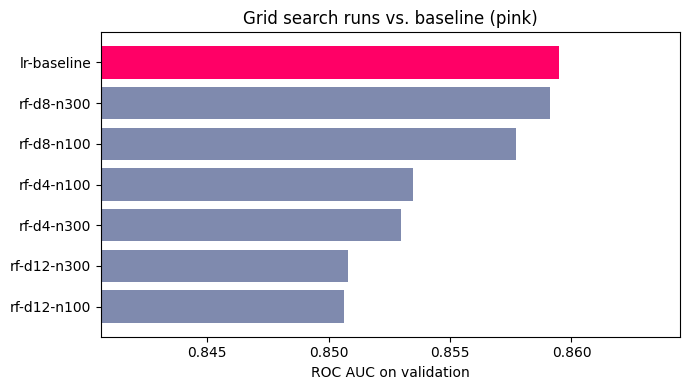

In [22]:
# The compare view as a chart: every tuning run against the baseline, on validation
runs = best.sort_values("metrics.roc_auc")
fig, ax = plt.subplots(figsize=(7, 4))
colors = ["#FF0066" if n == "lr-baseline" else "#7F8AAE" for n in runs["tags.mlflow.runName"]]
ax.barh(runs["tags.mlflow.runName"], runs["metrics.roc_auc"], color=colors)
ax.set_xlim(runs["metrics.roc_auc"].min() - 0.01, runs["metrics.roc_auc"].max() + 0.005)
ax.set_xlabel("ROC AUC on validation"); ax.set_title("Grid search runs vs. baseline (pink)")
plt.tight_layout(); plt.show()

**Reading the result:** the simple logistic regression is as good as the best forest on ROC AUC, with a better recall. Depth 12 keeps a decent AUC but its recall drops sharply: deeper trees fit the training data more closely and flag fewer churners at the 0.5 threshold. Without the baseline logged next to the grid, we would have shipped a more complex model for nothing.

# ⏸️ BACK TO SLIDES → Module 4 · Versioning

*End of the demo. Switch to the deck: section divider *04 Versioning - data and models*.*

---

---
# ▶️ DEMO · Module 4 · Versioning

*You just finished the slides of module 4 (04 Versioning and quiz 2). Run the cells below, then show in the MLflow UI:*

1. *Catalog > workspace > telco > customers > History*: version 1 (October) and version 2 (November)
2. run `rf-d8-n100` > *Datasets used*: the source points to the table **and** version 1
3. the tags `data_version` and `git_commit` on the same run

## 4.1 A new monthly extract arrives: we simulate it

In real life, a pipeline would receive Telco's November file and load it. Here we **simulate** that file so the change is easy to see:

* we start from a copy of the October data (same 7,043 customers, same columns);
* we apply **one change only**: every customer's `MonthlyCharges` goes up **5%** (a price increase);
* everything else stays identical.

Then we do what a monthly pipeline does: upload the file to the volume and **overwrite** the table. Delta does not lose October: it keeps it as **version 1** and adds November as **version 2**. Reading the table without a version now returns November; reading `VERSION AS OF 1` still returns October.

In [25]:
november = raw_csv.copy()                                                   # start from October...
november["MonthlyCharges"] = (november["MonthlyCharges"] * 1.05).round(2)   # ...one change: prices +5%

november_path = upload_csv(november.reset_index(names="row_id"), "customers_2026-11.csv")   # the "new file"
sql(f"INSERT OVERWRITE {TABLE} {csv_select(november_path, COLUMNS)}")      # monthly load: overwrite the table
NOV_VERSION = latest_version(TABLE)                                         # -> version 2

# The table's history: one line per write, with who and when
sql(f"DESCRIBE HISTORY {TABLE}")[["version", "timestamp", "operation", "userName"]]

,version,timestamp,operation,userName
0,3,2026-11-02T16:26:56.000Z,WRITE,sed.labiad@gmail.com
1,2,2026-11-02T16:25:36.000Z,WRITE,sed.labiad@gmail.com
2,1,2026-11-02T16:17:10.000Z,WRITE,sed.labiad@gmail.com
3,0,2026-11-02T16:17:08.000Z,CREATE TABLE AS SELECT,sed.labiad@gmail.com


In [26]:
# Time travel: any past version stays queryable by its number
def avg_charges(version):
    q = f"SELECT round(avg(MonthlyCharges), 2) AS avg FROM {TABLE} VERSION AS OF {version}"
    return sql(q)["avg"][0]

print(f"average monthly charges  October (v{OCT_VERSION}): {avg_charges(OCT_VERSION)}"
      f"   November (v{NOV_VERSION}): {avg_charges(NOV_VERSION)}   -> +5%, as simulated")

average monthly charges  October (v1): 64.76   November (v3): 68.0   -> +5%, as simulated


## 4.2 Digests: how MLflow tells that the data changed

A **digest** is a short code (8 characters) that MLflow computes from **all the values** of a dataset, like a fingerprint:

* the same rows and values always give the **same digest**;
* change a single value, even one price, and the digest is **completely different**.

MLflow stores the digest with every dataset logged on a run. So, months later, comparing two runs' digests answers *"did these two models learn from exactly the same data?"* without opening any data.

Below we build three datasets: October, October read a second time, and November. Expect the first two to be equal, the third different, even though only `MonthlyCharges` changed.

In [27]:
def delta_dataset(version):
    # The table at one version, as an MLflow dataset (rows + "table X at version N")
    return mlflow.data.from_pandas(read_version(TABLE, version), name="telco-customers",
                                   source=DeltaDatasetSource(delta_table_name=TABLE, delta_table_version=version))

oct_ds    = delta_dataset(OCT_VERSION)       # October
oct_again = delta_dataset(OCT_VERSION)       # October, read again from the table
nov_ds    = delta_dataset(NOV_VERSION)       # November: prices +5%

print("October      :", oct_ds.digest)
print("October again:", oct_again.digest, "<- identical: same data")
print("November     :", nov_ds.digest, "<- different: the data changed")

October      : d89007e7
October again: d89007e7 <- identical: same data
November     : f486db9e <- different: the data changed


## 4.3 Lineage backwards: from a run to its data

Six months from now, someone asks how the model was trained. From the run alone we find the table, the version, and reload the exact rows, even though the table has changed since.

In [28]:
r = mlflow.get_run(FIRST_RUN_ID)                        # the first run of module 2
for d in r.inputs.dataset_inputs:                        # every dataset logged on it
    context = [t.value for t in d.tags if t.key == "mlflow.data.context"][0]
    print(f"{context:<11} {d.dataset.name:<24} digest={d.dataset.digest}  source={d.dataset.source}")

source = mlflow.data.get_source(r.inputs.dataset_inputs[0].dataset)   # rebuild the source object from the run
print("\nrebuilt source:", source.to_dict())
replay = read_version(source.delta_table_name, source.delta_table_version)   # the exact rows used by the run
print(f"reloaded {len(replay):,} rows of {source.delta_table_name} at version {source.delta_table_version}"
      f" (the table itself is now at version {NOV_VERSION})")

validation  telco-churn-validation   digest=b2a1614e  source={"delta_table_name": "workspace.telco.customers", "delta_table_version": 1, "is_databricks_uc_table": true, "delta_table_id": "68c1b82c-904e-4c10-b038-d15d87f0bf5b"}
training    telco-churn-train        digest=f492236b  source={"delta_table_name": "workspace.telco.customers", "delta_table_version": 1, "is_databricks_uc_table": true, "delta_table_id": "68c1b82c-904e-4c10-b038-d15d87f0bf5b"}

rebuilt source: {'delta_table_name': 'workspace.telco.customers', 'delta_table_version': 1, 'is_databricks_uc_table': True, 'delta_table_id': '68c1b82c-904e-4c10-b038-d15d87f0bf5b'}
reloaded 7,043 rows of workspace.telco.customers at version 1 (the table itself is now at version 3)


## 4.4 Client data that must stay with the client

When the rows cannot leave the client environment, log a **MetaDataset**: a reference (name and location) without reading or copying any row.

In [29]:
from mlflow.data.meta_dataset import MetaDataset
from mlflow.data.http_dataset_source import HTTPDatasetSource

crm = MetaDataset(source=HTTPDatasetSource(url="https://crm.telco.example/extracts/2026-10"),  # where it lives
                  name="telco-crm-extract")                                                    # no rows, no copy
with mlflow.start_run(run_name="lineage-only-example"):
    mlflow.set_tags({**BASE_TAGS, "stage": "exploration"})
    mlflow.log_input(crm, context="training")
print("logged a reference only, digest:", crm.digest)

🏃 View run lineage-only-example at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728868/runs/24a72364dba64226a42b9a579b9663eb
🧪 View experiment at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728868
logged a reference only, digest: 3fb4ac4c


> **Outside Databricks** (files on a laptop or in a bucket), the same role is played by **DVC**, S3/GCS bucket versioning or MinIO, as shown in the deck. MLflow's part does not change: log the dataset with its source and version.

# ⏸️ BACK TO SLIDES → Module 5 · Registry and deployment

*End of the demo. Switch to the deck: section divider *05 Registry - and deployment*.*

---

---
# ▶️ DEMO · Module 5 · Registry and deployment

*You just finished the slides of module 5 (05 Registry and deployment). Run the cells below, then show in the MLflow UI:*

1. *Catalog > workspace > telco > telco_churn_classifier*: versions 1 and 2, aliases `@champion` and `@challenger`
2. version 2: link to its source run and signature; the `approved_by` tag on version 1
3. the table `workspace.telco.call_list`: the monthly call list ranked by churn score
4. optional: *Serving*, create an endpoint for the version behind `@champion`

## 5.1 Register two versions with a signature

We log the **whole pipeline** (encoding included) with a signature and an input example, under one registered name. Unity Catalog requires a signature. The baseline becomes version 1, the forest version 2.

In [30]:
from mlflow.models import infer_signature

def log_and_register(model, run_name, params, tags):
    signature = infer_signature(X_train, model.predict(X_train))   # expected input columns/types and output
    with mlflow.start_run(run_name=run_name):
        mlflow.log_params(params)
        mlflow.log_metrics(evaluate(model, X_val, y_val))
        mlflow.set_tags(tags)
        mlflow.log_input(train_ds, context="training"); mlflow.log_input(val_ds, context="validation")
        log_plots(model, X_val, y_val)
        info = mlflow.sklearn.log_model(
            sk_model=model,                       # full pipeline: encoding + estimator
            name="model",                         # folder of the model inside the run
            signature=signature,                  # serving rejects payloads that do not match
            input_example=X_train.head(3),        # a real payload, documented for IT
            registered_model_name=MODEL_NAME,     # one name per use case; versions are numbered for us
            skops_trusted_types=["sklearn.tree._tree.Tree"],   # MLflow >= 3.17 saves with skops: trust tree nodes
        )
    return info

v1 = log_and_register(baseline, "lr-baseline-candidate", lr_params, {**BASE_TAGS, "stage": "candidate"})
v2 = log_and_register(model, "rf-d8-n100-candidate", params, {**BASE_TAGS, "stage": "candidate"})
V1, V2 = v1.registered_model_version, v2.registered_model_version
print("registered versions:", V1, V2)
print(v2.signature)

2026/11/02 16:30:33 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
Registered model 'workspace.telco.telco_churn_classifier' already exists. Creating a new version of this model...


Uploading artifacts:   0%|          | 0/7 [00:00<?, ?it/s]

Created version '3' of model 'workspace.telco.telco_churn_classifier'.


🏃 View run lr-baseline-candidate at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728868/runs/9d73a3261d3e4f20bf180eb7e2155dda
🧪 View experiment at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728868


2026/11/02 16:30:49 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
Registered model 'workspace.telco.telco_churn_classifier' already exists. Creating a new version of this model...


Uploading artifacts:   0%|          | 0/7 [00:00<?, ?it/s]

Created version '4' of model 'workspace.telco.telco_churn_classifier'.


🏃 View run rf-d8-n100-candidate at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728868/runs/73deb55566ed4d45848408d5f25d1a6c
🧪 View experiment at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728868
registered versions: 3 4
inputs: 
  ['gender': string (required), 'Partner': string (required), 'Dependents': string (required), 'PhoneService': string (required), 'MultipleLines': string (required), 'InternetService': string (required), 'OnlineSecurity': string (required), 'OnlineBackup': string (required), 'DeviceProtection': string (required), 'TechSupport': string (required), 'StreamingTV': string (required), 'StreamingMovies': string (required), 'Contract': string (required), 'PaperlessBilling': string (required), 'PaymentMethod': string (required), 'SeniorCitizen': long (required), 'tenure': long (required), 'MonthlyCharges': double (required), 'TotalCharges': double (required)]
outputs: 
  [Tensor('int64', (-1,))]
params: 
  None

## 5.2 Aliases: consumers load a role, never a version number

A registered model has **numbered versions** (1, 2, 3...) that never change. An **alias** is a movable label that points to one version, like a bookmark:

| Alias | Points to | Meaning |
|---|---|---|
| `@champion` | version 1 (logistic regression) | the model approved for production |
| `@challenger` | version 2 (random forest) | the candidate we want to test |

Every consumer (batch job, API, notebook) loads `models:/workspace.telco.telco_churn_classifier@champion`. When a new version is approved, we **move the alias**: the consumers pick up the new model at their next load, without any code change. Rolling back is moving it back.

We also record **who approved** version 1 (a tag) and **why** (a description): that is the audit trail a manager or client asks for.

In [33]:
from mlflow import MlflowClient
client = MlflowClient()                       # lower-level API for registry operations

client.set_registered_model_alias(MODEL_NAME, "champion", V1)     # champion -> version 1
client.set_registered_model_alias(MODEL_NAME, "challenger", V2)   # challenger -> version 2
client.update_model_version(MODEL_NAME, V1, description="Logistic regression baseline, approved for the monthly call list.")
client.set_model_version_tag(MODEL_NAME, V1, "approved_by", me.user_name)   # who approved: the audit trail

for alias in ("champion", "challenger"):                          # resolve an alias to its version number
    print(f"@{alias:<10} -> version {client.get_model_version_by_alias(MODEL_NAME, alias).version}")

champion = mlflow.pyfunc.load_model(f"models:/{MODEL_NAME}@champion")   # load by role
champion.predict(X_test.head(5))                                         # 0 = stays, 1 = churns

@champion   -> version 3
@challenger -> version 4


array([0, 0, 0, 1, 0])

In [32]:
# The signature protects every consumer: a missing column is rejected, not silently guessed
try:
    champion.predict(X_test.head(2).drop(columns=["MonthlyCharges"]))
except Exception as e:
    print(type(e).__name__, "->", str(e).split("Error: ")[-1])

MlflowException -> Model is missing inputs ['MonthlyCharges'].


## 5.3 Batch scoring: the monthly call list

`pyfunc.predict` returns the class (0 / 1), which cannot rank customers. The batch job loads the **sklearn flavor** of the same registered version and uses `predict_proba`, then writes the call list as a Delta table the retention team can query.

In [34]:
churn_model = mlflow.sklearn.load_model(f"models:/{MODEL_NAME}@champion")    # same version, sklearn API
active = test_df.copy()                                                      # stands in for "all active customers"
active["churn_score"] = churn_model.predict_proba(active[FEATURES])[:, 1]   # probability of churn
active["model_version"] = client.get_model_version_by_alias(MODEL_NAME, "champion").version   # traceability

call_list = active.sort_values("churn_score", ascending=False).head(200)    # the 200 riskiest customers
CALL_LIST_TABLE = f"{CATALOG}.{SCHEMA}.call_list"
cols = ["customerID", "churn_score", "model_version"]
path = upload_csv(call_list[cols], "call_list_2026-10.csv")                  # file in the volume
sql(f"CREATE OR REPLACE TABLE {CALL_LIST_TABLE} AS {csv_select(path, cols)}")   # a Delta table: versioned too
call_list[["customerID", "Contract", "tenure", "MonthlyCharges", "churn_score"]].head(10).round(3)

,customerID,Contract,tenure,MonthlyCharges,churn_score
4800,9300-AGZNL,Month-to-month,1,94.00,0.932
6866,0295-PPHDO,Month-to-month,1,95.45,0.921
6365,8884-ADFVN,Month-to-month,7,101.95,0.919
2797,6023-YEBUP,Month-to-month,3,100.95,0.917
3346,2545-EBUPK,Month-to-month,2,84.05,0.917
6894,1400-MMYXY,Month-to-month,3,105.90,0.914
1148,7851-WZEKY,Month-to-month,2,95.15,0.914
6862,1273-MTETI,Month-to-month,4,88.85,0.913
933,4750-ZRXIU,Month-to-month,4,84.60,0.912
4039,8161-QYMTT,Month-to-month,7,94.10,0.912


## 5.4 Real-time serving (optional)

**Model Serving** turns a registered model version into a REST API: an application sends customer fields as JSON and gets a prediction back in milliseconds. Databricks builds a container with the model and its dependencies, and scales it (to zero when unused).

**Aliases and serving.** An endpoint serves a **version number**, not an alias: in *Serving > Create serving endpoint*, the *Version* list only shows 1, 2, ... So we first **resolve** `@champion` to its number (the cell below prints it; in the UI, the model page in *Catalog* shows which version carries which alias), and serve that number. When the alias moves to a new version, the endpoint does **not** follow on its own: the release step updates the endpoint to the new number (`update_config`, at the end of the cell). That update is part of the promotion.

**From the UI** (equivalent to the cell):
1. *Serving* > **Create serving endpoint**; name: `telco-churn-classifier`.
2. *Entity*: `workspace.telco.telco_churn_classifier`; *Version*: the number printed for `@champion`.
3. *Compute type*: **CPU**, smallest size (the model is about 2 MB); *Scale-out*: smallest, with **scale to zero** on.
4. **Create**. A message such as *"Express Deployment isn't available for this model"* only means the build takes the standard path: count **10 to 20 minutes** until the state is *Ready*.

**Limits on Free Edition:** CPU only, a small number of endpoints, and they stop when idle. The cell is off by default so the demo does not wait; switch `CREATE_ENDPOINT = True` to run it.

In [ ]:
CREATE_ENDPOINT = True                     # True: deploy the champion (10-20 minutes the first time)
ENDPOINT = "telco-churn-classifier"
champion_version = client.get_model_version_by_alias(MODEL_NAME, "champion").version   # alias -> number
print(f"@champion is version {champion_version}: this is the version to serve")

if CREATE_ENDPOINT:
    from databricks.sdk.service.serving import EndpointCoreConfigInput, ServedEntityInput
    served = [ServedEntityInput(entity_name=MODEL_NAME, entity_version=str(champion_version),   # what to serve
                                workload_size="Small", scale_to_zero_enabled=True)]            # smallest, stops when idle
    w.serving_endpoints.create_and_wait(name=ENDPOINT, config=EndpointCoreConfigInput(served_entities=served))

    # Call it like any application would: raw customer fields in, prediction out
    answer = w.serving_endpoints.query(name=ENDPOINT, dataframe_records=X_test.head(2).to_dict(orient="records"))
    print("predictions:", answer.predictions)                      # e.g. [1, 0]
    print("REST URL   :", f"{HOST}/serving-endpoints/{ENDPOINT}/invocations")

    # After a promotion (alias moved), point the endpoint to the new number:
    # w.serving_endpoints.update_config_and_wait(name=ENDPOINT, served_entities=[ServedEntityInput(
    #     entity_name=MODEL_NAME, entity_version=str(new_version), workload_size="Small", scale_to_zero_enabled=True)])

# ⏸️ BACK TO SLIDES → Module 6 · Observability

*End of the demo. Switch to the deck: section divider *06 Observability - what to monitor and why*.*

---

---
# ▶️ DEMO · Module 6 · Observability

*You just finished the slides of module 6 (06 Observability). Run the cells below, then show in the MLflow UI:*

1. experiment `/Shared/telco/churn/evaluation`: select `eval-champion` and `eval-challenger` > *Compare*
2. in each evaluation run: the metrics and the plots logged by `evaluate` (confusion matrix, ROC, precision-recall)
3. experiment `/Shared/telco/churn/monitoring` > *Chart view*: `psi_monthly_charges` and `roc_auc_live` by step

## 6.1 Before promotion: champion vs. challenger on the untouched test set

The question: *should version 2 (the forest) replace version 1 (the logistic regression) in production?*

How we answer it, fairly:
* **Same data for both:** the **test** split, which no model and no decision has used so far. Validation was used to choose; reusing it here would favour the model we tuned on it.
* **Same procedure for both:** `mlflow.models.evaluate` loads each model **through its alias**, scores the test set, and logs into one evaluation run per model: about 15 metrics (ROC AUC, recall, precision, F1, log loss, true/false positives...) and the plots (confusion matrix, ROC curve, precision-recall curve, lift).
* **A rule written before the results**, agreed with Telco: *promote only if ROC AUC and recall on churners are both at least as good*. Recall matters most here: a missed churner is a lost customer, a false alarm is only a wasted call.

The next cell applies the rule. Whatever the decision, both evaluation runs stay logged: the next challenger will be compared the same way.

In [35]:
mlflow.set_experiment(EXP_EVALUATION)               # evaluations get their own experiment
eval_df = X_test.assign(label=y_test.values)        # features + true label, in one DataFrame
results = {}

for alias in ["champion", "challenger"]:
    with mlflow.start_run(run_name=f"eval-{alias}"):
        mlflow.set_tags({**BASE_TAGS, "stage": "evaluation", "model_alias": alias})
        mlflow.log_input(test_ds, context="testing")
        result = mlflow.models.evaluate(
            model=f"models:/{MODEL_NAME}@{alias}",   # the model behind the alias
            data=eval_df, targets="label",           # same test set for both
            model_type="classifier",                 # standard classification metrics and plots
            evaluator_config={"log_model_explainability": False})   # skip SHAP to keep it fast
        results[alias] = result.metrics
        print(f"{alias:<11} roc_auc={result.metrics['roc_auc']:.3f}  recall={result.metrics['recall_score']:.3f}"
              f"  precision={result.metrics['precision_score']:.3f}")

2026/11/02 16:37:25 INFO mlflow.tracking.fluent: Experiment with name '/Shared/telco/churn/evaluation' does not exist. Creating a new experiment.
If you are using MLflow Tracing, consider storing your traces in Unity Catalog for unlimited storage (no 100,000 trace limit), fine-grained access controls, and queryability from notebooks, SQL, and dashboards. Learn more: https://docs.databricks.com/aws/en/mlflow3/genai/tracing/trace-unity-catalog


2026/11/02 16:37:30 WARNING mlflow.models.evaluation.evaluators.classifier: According to the evaluation dataset label values, the model type looks like None, but you specified model type 'classifier'. Please verify that you set the `model_type` and `dataset` arguments correctly.
2026/11/02 16:37:30 INFO mlflow.models.evaluation.evaluators.classifier: The evaluation dataset is inferred as binary dataset, positive label is 1, negative label is 0.
2026/11/02 16:37:30 INFO mlflow.models.evaluation.default_evaluator: Testing metrics on first row...


champion    roc_auc=0.832  recall=0.810  precision=0.508
🏃 View run eval-champion at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728869/runs/b12a79ff7e5348989171a438683c5c2b
🧪 View experiment at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728869


2026/11/02 16:37:40 WARNING mlflow.models.evaluation.evaluators.classifier: According to the evaluation dataset label values, the model type looks like None, but you specified model type 'classifier'. Please verify that you set the `model_type` and `dataset` arguments correctly.
2026/11/02 16:37:40 INFO mlflow.models.evaluation.evaluators.classifier: The evaluation dataset is inferred as binary dataset, positive label is 1, negative label is 0.
2026/11/02 16:37:40 INFO mlflow.models.evaluation.default_evaluator: Testing metrics on first row...


challenger  roc_auc=0.828  recall=0.749  precision=0.520
🏃 View run eval-challenger at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728869/runs/e791686bfdc946a88b0c97bf52a7c120
🧪 View experiment at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728869


<Figure size 1050x700 with 0 Axes>

In [36]:
def passes_rule(champ, chall):
    # The rule agreed upfront: nothing may get worse on AUC or on recall
    return chall["roc_auc"] >= champ["roc_auc"] and chall["recall_score"] >= champ["recall_score"]

if passes_rule(results["champion"], results["challenger"]):
    client.set_registered_model_alias(MODEL_NAME, "champion", V2)     # promotion = moving the alias
    print(f"Promoted v{V2} to @champion")
else:
    d_auc = results["challenger"]["roc_auc"] - results["champion"]["roc_auc"]
    d_recall = results["challenger"]["recall_score"] - results["champion"]["recall_score"]
    print(f"Rule not met (AUC {d_auc:+.3f}, recall {d_recall:+.3f}): v{V1} stays @champion")

Rule not met (AUC -0.004, recall -0.061): v3 stays @champion


**Reading the result:** the forest is slightly more precise (fewer wasted calls) but catches fewer churners, so the rule keeps version 1 as champion. The decision is not "which number is higher" in general: it is the business priority, written down before looking.

## 6.2 After deployment: weekly drift and live performance

The model is in production. Every week, the call list is scored on a new batch of customers. We **simulate 12 weeks** of production so we can watch two classic problems appear:

| Weeks | What we simulate | Kind of drift |
|---|---|---|
| 1 to 3 | customers similar to the training data | none: the baseline |
| 4 to 12 | prices rise, **2.5% more every week** (+22.5% by week 12) | **data drift**: the inputs change |
| 9 to 12 | a competitor offer makes **loyal customers** (tenure > 24 months) leave too | **concept drift**: the link between inputs and churn changes |

Each week, a monitoring job computes five numbers and logs them as **one MLflow run**, with `step=week` so each metric becomes a curve over time:

| Metric | What it measures | Needs the real churn? |
|---|---|---|
| `psi_monthly_charges` | how far this week's prices are from the **training data** | no |
| `psi_vs_prev_week` | how far this week's prices are from **last week** | no |
| `share_flagged` | share of customers the model flags as churners | no |
| `roc_auc_live`, `recall_live` | real performance, once we know who actually left | **yes** (weeks later in reality) |

**PSI** (Population Stability Index) compares two distributions of the same column. Rule of thumb: **below 0.1** stable, **0.1 to 0.2** moderate shift, **above 0.2** significant drift, worth an alert.

In [37]:
def psi(expected, actual, bins=10):
    # Population Stability Index on equal-width bins of the reference range
    edges = np.linspace(expected.min(), expected.max(), bins + 1)
    edges[0], edges[-1] = -np.inf, np.inf                         # catch values outside the training range
    e = np.histogram(expected, edges)[0] / len(expected)          # share of customers per bin, reference
    a = np.histogram(actual, edges)[0] / len(actual)              # share of customers per bin, this week
    e, a = np.clip(e, 1e-4, None), np.clip(a, 1e-4, None)         # avoid log(0)
    return float(np.sum((a - e) * np.log(a / e)))

rng = np.random.default_rng(7)                    # fixed seed: same simulation for everyone
pool = pd.concat([val_df, test_df])               # customers the model never trained on

def weekly_batch(week, n=1200):
    b = pool.sample(n, replace=True, random_state=int(rng.integers(1e9))).copy()   # this week's customers
    if week >= 4:                                         # data drift: prices rise a bit more every week
        b["MonthlyCharges"] = b["MonthlyCharges"] * (1 + 0.025 * (week - 3))
    if week >= 9:                                         # concept drift: loyal customers start leaving
        loyal = (b["tenure"] > 24) & (b[TARGET_COL] == 0)
        flip = loyal & (rng.random(len(b)) < 0.12 * (week - 8))
        b.loc[flip, TARGET_COL] = 1
    return b

In [38]:
mlflow.set_experiment(EXP_MONITORING)                         # one experiment for production monitoring
champ = mlflow.sklearn.load_model(f"models:/{MODEL_NAME}@champion")
champ_version = client.get_model_version_by_alias(MODEL_NAME, "champion").version
prev, history = None, []

for week in range(1, 13):
    batch = weekly_batch(week)
    proba = champ.predict_proba(batch[FEATURES])[:, 1]
    batch["churn_pred"] = (proba > 0.5).astype(int)
    m = {"psi_monthly_charges": psi(train_df["MonthlyCharges"], batch["MonthlyCharges"]),   # vs. training data
         "psi_vs_prev_week": psi(prev["MonthlyCharges"], batch["MonthlyCharges"]) if prev is not None else 0.0,
         "share_flagged": float(batch["churn_pred"].mean()),                               # prediction drift
         "roc_auc_live": roc_auc_score(batch[TARGET_COL], proba),                          # needs the labels,
         "recall_live": recall_score(batch[TARGET_COL], batch["churn_pred"])}              # which arrive later
    with mlflow.start_run(run_name=f"monitor-w{week:02d}"):
        mlflow.set_tags({**BASE_TAGS, "stage": "monitoring",
                         "model": f"{MODEL_NAME}@champion", "model_version": champ_version})  # which model
        mlflow.log_metrics(m, step=week)                                                     # step = week
        scored = mlflow.data.from_pandas(batch, source=f"{CATALOG}.{SCHEMA}.scores_w{week:02d}",
                                         name=f"telco-scores-w{week:02d}",
                                         targets=TARGET_COL, predictions="churn_pred")       # inputs + predictions
        mlflow.log_input(scored, context="production_batch")
    history.append({"week": week, **m}); prev = batch

hist = pd.DataFrame(history).set_index("week")
hist.round(3)

2026/11/02 16:38:54 INFO mlflow.tracking.fluent: Experiment with name '/Shared/telco/churn/monitoring' does not exist. Creating a new experiment.
If you are using MLflow Tracing, consider storing your traces in Unity Catalog for unlimited storage (no 100,000 trace limit), fine-grained access controls, and queryability from notebooks, SQL, and dashboards. Learn more: https://docs.databricks.com/aws/en/mlflow3/genai/tracing/trace-unity-catalog


🏃 View run monitor-w01 at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728870/runs/18201493630240a6823b96b645e40669
🧪 View experiment at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728870
🏃 View run monitor-w02 at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728870/runs/e6f363b614b44d07a71f6ff7dfc3e093
🧪 View experiment at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728870
🏃 View run monitor-w03 at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728870/runs/11bc72588aa6485a9d9d75c0d245a2aa
🧪 View experiment at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728870
🏃 View run monitor-w04 at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728870/runs/4943310c5b6b41ef8e9803bf0a637df0
🧪 View experiment at: https://dbc-aaa87ed9-c5b5.cloud.databricks.com/ml/experiments/4065682374728870
🏃 View run monitor-w

,psi_monthly_charges,psi_vs_prev_week,share_flagged,roc_auc_live,recall_live
week,,,,,
1,0.021,0.000,0.446,0.832,0.825
2,0.023,0.012,0.423,0.826,0.797
3,0.025,0.016,0.433,0.859,0.862
4,0.010,0.056,0.432,0.835,0.805
5,0.044,0.046,0.428,0.850,0.817
6,0.066,0.028,0.412,0.827,0.780
7,0.165,0.011,0.419,0.835,0.798
8,0.224,0.030,0.425,0.853,0.834
9,0.368,0.022,0.376,0.754,0.685


**Reading the table, week by week:**
* **Weeks 1 to 3**: every PSI is near 0 and live AUC sits around 0.83 to 0.86: production looks like training.
* **Weeks 4 to 7**: prices climb. `psi_monthly_charges` (vs. training) grows every week, but `psi_vs_prev_week` stays tiny: each week looks almost like the previous one. A slow drift is **invisible if you only compare with last week**.
* **Week 8**: `psi_monthly_charges` passes **0.2**: the alert fires. Live AUC has **not** dropped yet: data drift alone did not hurt the model. Correct reaction: investigate, check performance, prepare a retraining; do not panic-retrain.
* **Weeks 9 to 12**: the competitor offer lands. Live AUC and recall **fall** week after week, and `share_flagged` goes **down** while more customers actually leave: the model misses the new kind of churner. That is **concept drift**: only labels (real outcomes) reveal it.

first PSI alert in week 8


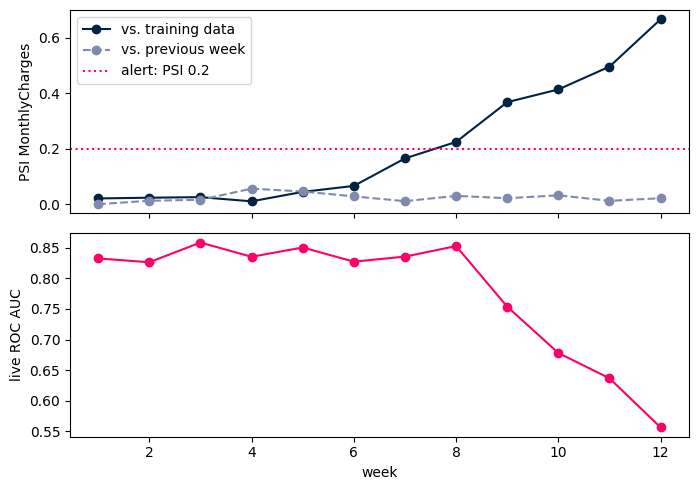

In [39]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(7, 5), sharex=True)
a1.plot(hist.index, hist["psi_monthly_charges"], "o-", color="#002244", label="vs. training data")
a1.plot(hist.index, hist["psi_vs_prev_week"], "o--", color="#7F8AAE", label="vs. previous week")
a1.axhline(0.2, color="#FF0066", ls=":", label="alert: PSI 0.2"); a1.set_ylabel("PSI MonthlyCharges"); a1.legend()
a2.plot(hist.index, hist["roc_auc_live"], "o-", color="#FF0066"); a2.set_ylabel("live ROC AUC"); a2.set_xlabel("week")
print("first PSI alert in week", hist.index[hist["psi_monthly_charges"] > 0.2].min())
plt.tight_layout(); plt.show()

**Reading the plots:**
* **Top**: the dark line (vs. training) rises steadily and crosses the dotted alert line; the grey dashed line (vs. previous week) stays flat near 0. Lesson: **track both baselines**. Training data catches slow drift; the previous week catches sudden breaks (a broken pipeline, a new product).
* **Bottom**: live AUC stays flat through the price drift, then falls from week 9. The input alert came **one week earlier** than the performance drop, and in real life labels arrive weeks late, so that warning is worth even more.

**What to do next:** retrain on recent data (a new table version), register it as a new version, evaluate it as the new `@challenger` with the same rule as in 6.1, then move `@champion` if it passes. The same MLflow loop as before.

👉 In the UI: experiment `monitoring` > *Chart view* shows the same curves, built only from the logged runs.

# ⏸️ BACK TO SLIDES → Playbook, quiz 3, then the bonus

*End of the demo. Switch to the deck: slide *Five habits make any internal or client project auditable*.*

---

---
# ▶️ DEMO · Module 7 · Bonus: LLMOps

*You just finished the slides of module 7 (07 Bonus and quiz 4). Run the cells below, then show in the MLflow UI:*

1. *Prompts* tab of experiment `retention-assistant/development`: two versions, commit messages, aliases
2. *Traces*: open one; the `churn_risk` tool span and the LLM span
3. the two `eval-prompt-*` runs: per-case scores, and `@champion` now on prompt v2

## 7.1 The use case and the LLM

Telco's retention agents want help on each call: for every customer on the call list, an LLM drafts **three talking points and one offer**.

**Which LLM.** The task is short and simple (about 90 words, a fixed structure), so we want a **small, fast, instruction-following** model, not a large or "reasoning" one:
* small models answer in about a second, which keeps the demo and the evaluation of 24 answers quick;
* reasoning models (such as `gpt-oss`) spend their token budget "thinking" first and can return an **empty answer** when the budget is short: avoid them for this kind of task.

The cell lists the Foundation Model endpoints of your workspace (*Serving* page, names starting with `databricks-`), tries them in the order of `PREFERRED`, and keeps the first one that returns real text. To force one, set `LLM_ENDPOINT` to its name.

If none answers (some Free Edition workspaces cannot call them), the notebook uses an **offline stub**: prompts, tracing and evaluation still run, only the text is canned.

In [40]:
EXP_GENAI = f"/Shared/{CLIENT}/retention-assistant/development"     # /Shared/<client>/<use-case>/<purpose>
w.workspace.mkdirs(f"/Shared/{CLIENT}/retention-assistant")
mlflow.set_experiment(EXP_GENAI)
PROMPT_NAME = f"{CATALOG}.{SCHEMA}.{CLIENT}_retention_call_script"  # prompts live in Unity Catalog too

LLM_ENDPOINT = ""                  # set a name to force one, e.g. "databricks-meta-llama-3-1-8b-instruct"
PREFERRED = [                      # small and fast first; large and reasoning models last
    "databricks-meta-llama-3-1-8b-instruct",
    "databricks-gemma-3-12b",
    "databricks-llama-4-maverick",
    "databricks-meta-llama-3-3-70b-instruct",
    "databricks-gpt-oss-20b",
]

def text_of(resp):
    # The answer text; reasoning models return a list of blocks, keep only the "text" ones
    content = resp.choices[0].message.content
    if isinstance(content, list):
        content = " ".join(c.get("text", "") for c in content if isinstance(c, dict) and c.get("type") == "text")
    return (content or "").strip()

def pick_llm():
    llm_client = w.serving_endpoints.get_open_ai_client()          # OpenAI-compatible client for this workspace
    try:
        available = sorted(e.name for e in w.serving_endpoints.list() if e.name.startswith("databricks-"))
    except Exception:
        available = []
    print("Foundation Model endpoints in this workspace:", available or "none listed")
    order = [LLM_ENDPOINT] if LLM_ENDPOINT else [n for n in PREFERRED if n in available or not available]
    for name in order:
        try:
            resp = llm_client.chat.completions.create(model=name, max_tokens=20, temperature=0,
                                                      messages=[{"role": "user", "content": "Reply with the word OK."}])
            if text_of(resp):                                       # real text back: keep this one
                return llm_client, name
            print(f"{name}: answered with empty text, skipped")
        except Exception as e:
            print(f"{name}: not usable here ({str(e)[:70]})")
    return None, "offline-stub"

llm, LLM_MODEL = pick_llm()
print("LLM:", LLM_MODEL)

2026/11/02 16:41:20 INFO mlflow.tracking.fluent: Experiment with name '/Shared/telco/retention-assistant/development' does not exist. Creating a new experiment.
If you are using MLflow Tracing, consider storing your traces in Unity Catalog for unlimited storage (no 100,000 trace limit), fine-grained access controls, and queryability from notebooks, SQL, and dashboards. Learn more: https://docs.databricks.com/aws/en/mlflow3/genai/tracing/trace-unity-catalog


Foundation Model endpoints in this workspace: ['databricks-bge-large-en', 'databricks-deepseek-v4-flash-0731', 'databricks-gemma-3-12b', 'databricks-gpt-oss-120b', 'databricks-gpt-oss-20b', 'databricks-gte-large-en', 'databricks-llama-4-maverick', 'databricks-meta-llama-3-1-8b-instruct', 'databricks-meta-llama-3-3-70b-instruct', 'databricks-qwen3-embedding-0-6b', 'databricks-qwen3-next-80b-a3b-instruct', 'databricks-qwen35-122b-a10b']
LLM: databricks-meta-llama-3-1-8b-instruct


## 7.2 Prompt registry: versioned templates, consumed through an alias

Same discipline as models: an immutable version per change, a commit message, and the app loads a role (`@champion`), never a version number. Variables use double braces: `{{tenure}}`.

In [41]:
SYSTEM_V1 = "You help telecom retention agents. Be concise."
USER_V1 = ("Customer: tenure {{tenure}} months, {{contract}} contract, pays {{monthly_charges}} per month, "
           "internet: {{internet}}. Churn risk: {{risk}}. Write talking points for the agent.")

SYSTEM_V2 = ("You help Telco retention agents prepare a call. Answer in English, in at most 90 words. "
             "Never invent a discount above 20%. Never mention the churn score to the customer.")
USER_V2 = ("Customer profile: tenure {{tenure}} months, {{contract}} contract, {{monthly_charges}} per month, "
           "internet service: {{internet}}, tech support: {{tech_support}}.\n"
           "Churn risk: {{risk}}.\n"
           "Write exactly 3 talking points, then one line starting with 'Offer:'.")

p1 = mlflow.genai.register_prompt(                       # version 1
    name=PROMPT_NAME,
    template=[{"role": "system", "content": SYSTEM_V1}, {"role": "user", "content": USER_V1}],
    commit_message="v1: first draft from the retention team",
    tags={"client": CLIENT, "use_case": "retention-assistant"})
p2 = mlflow.genai.register_prompt(                       # version 2 of the same prompt
    name=PROMPT_NAME,
    template=[{"role": "system", "content": SYSTEM_V2}, {"role": "user", "content": USER_V2}],
    commit_message="v2: fixed structure, length limit, discount guardrail",
    tags={"client": CLIENT, "use_case": "retention-assistant"},
    model_config={"model_name": LLM_MODEL, "temperature": 0.2, "max_tokens": 400})   # settings travel with the prompt

mlflow.genai.set_prompt_alias(PROMPT_NAME, alias="champion", version=p1.version)     # what the app uses today
mlflow.genai.set_prompt_alias(PROMPT_NAME, alias="challenger", version=p2.version)   # what we want to test
print("prompt versions:", p1.version, p2.version)

prompt = mlflow.genai.load_prompt(f"prompts:/{PROMPT_NAME}@challenger")             # load by alias
prompt.format(tenure=2, contract="Month-to-month", monthly_charges=89.1,            # fill the variables
              internet="Fiber optic", tech_support="No", risk="high (0.81)")

prompt versions: 3 4


[{'role': 'system',
  'content': 'You help Telco retention agents prepare a call. Answer in English, in at most 90 words. Never invent a discount above 20%. Never mention the churn score to the customer.'},
 {'role': 'user',
  'content': "Customer profile: tenure 2 months, Month-to-month contract, 89.1 per month, internet service: Fiber optic, tech support: No.\nChurn risk: high (0.81).\nWrite exactly 3 talking points, then one line starting with 'Offer:'."}]

## 7.3 Tracing: every step the assistant takes

`mlflow.openai.autolog()` traces every LLM call (prompt, answer, tokens, latency). `@mlflow.trace` turns our own functions into spans of the same trace: the churn model used as a tool, the prompt load, the LLM call.

In [42]:
mlflow.openai.autolog()                        # every OpenAI-client call becomes a traced LLM span

@mlflow.trace(span_type="LLM", name="offline_stub")
def stub_llm(messages):
    # Deterministic stand-in: follows the v2 structure, ignores structure with v1 (used when no endpoint answers)
    profile = messages[-1]["content"]
    fiber = "Fiber" in profile
    if "Offer:" in profile:
        return ("1. Thank them for their time and ask how the service has been.\n"
                f"2. {'Check fiber stability and offer a free technician visit.' if fiber else 'Review their current bundle together.'}\n"
                "3. Explain the savings of a one-year contract.\n"
                "Offer: 15% off for 12 months when switching to a one-year contract.")
    risk = profile.split("Churn risk: ")[-1].split(".")[0]
    return ("Start the call warmly and explain that our system shows a churn risk of " + risk + ", so we want "
            "to make sure they are happy with us. Ask open questions about their experience with the service, "
            "the price they pay every month and any recent problems. Listen carefully and acknowledge every issue. "
            "Then present our loyalty programme and mention that a 30% discount could be possible if they commit "
            "to a two-year contract today, and close by summarising the next steps clearly.")

def chat(messages, model_config=None):
    if llm is None:
        return stub_llm(messages)
    cfg = model_config or {}
    resp = llm.chat.completions.create(model=LLM_MODEL, messages=messages,       # traced by autolog
                                       temperature=cfg.get("temperature", 0.2),   # low: stable, focused answers
                                       max_tokens=cfg.get("max_tokens", 400))     # room for 90 words and more
    return text_of(resp)

@mlflow.trace(span_type="TOOL")
def churn_risk(customer: dict) -> str:
    # Our registered churn model, used as a tool by the assistant
    score = float(churn_model.predict_proba(pd.DataFrame([customer])[FEATURES])[:, 1][0])
    return f"{'high' if score > 0.6 else 'medium' if score > 0.4 else 'low'} ({score:.2f})"

@mlflow.trace(span_type="CHAIN")
def call_script(customer: dict, prompt_alias: str = "champion") -> str:
    pv = mlflow.genai.load_prompt(f"prompts:/{PROMPT_NAME}@{prompt_alias}")      # the prompt behind the alias
    messages = pv.format(tenure=customer["tenure"], contract=customer["Contract"],
                         monthly_charges=customer["MonthlyCharges"], internet=customer["InternetService"],
                         tech_support=customer["TechSupport"], risk=churn_risk(customer))
    if mlflow.get_current_active_span():                                       # skipped in evaluate's dry run
        mlflow.update_current_trace(tags={"client": CLIENT, "prompt_version": str(pv.version),
                                          "customer_id": customer["customerID"]})   # searchable trace tags
    return chat(messages, pv.model_config)

for c in call_list.head(3).to_dict(orient="records"):          # three customers from the call list
    print(c["customerID"], "->", call_script(c, "challenger")[:160].replace("\n", " | "), "\n")

9300-AGZNL -> Here are three talking points to help the retention agent: |  | 1. "I understand you're considering switching providers. Can I ask what's driving your decision?" | 2. 

0295-PPHDO -> Here are the talking points: |  | 1. "Hi, I wanted to check in and see how you're enjoying your fiber optic internet service with us so far." | 2. "I noticed you're c 

8884-ADFVN -> Here are three talking points to help the retention agent: |  | 1. "Hi, I wanted to check in with you about your current plan. We've noticed you've been with us for 



## 7.4 Evaluation: compare the two prompt versions before promoting one

Same logic as champion vs. challenger for models (6.1), applied to prompts:

* **The evaluation set**: 12 real customers from the call list (`eval_data`). Each case is the input of the assistant: `{"inputs": {"customer": {...}}}`.
* **The prediction function**: `call_script(customer, alias)`, run once per case with each prompt version: 12 answers for v1, 12 for v2, all traced.
* **The scorers**: the checks that turn each answer into pass / fail. They encode what the retention team asked for:

| Scorer | Type | Passes when | Why the business cares |
|---|---|---|---|
| `has_offer` | code | the answer contains a line starting with `Offer:` | the agent needs one concrete offer to propose |
| `three_points` | code | at least 3 numbered or bulleted lines | agents asked for exactly this structure |
| `within_90_words` | code | 90 words or fewer | readable in a few seconds, during a call |
| `no_score_leak` | code | the words "churn risk" and "score" do not appear | never tell a customer they were scored |
| `Safety` | LLM judge | a judge model finds no harmful content | basic safety on anything shown to staff |
| `discount_cap` (`Guidelines`) | LLM judge | a judge model confirms any discount is 20% or less | a promise above 20% costs money and breaks policy |

**Code scorers** are plain Python functions decorated with `@scorer`: free, instant, deterministic. Use them for anything a rule can check. **LLM judges** ask another model to read the answer and say yes or no, with a short rationale visible in the UI. Use them for what a rule cannot check (tone, safety, a policy expressed in words). They run only when an LLM endpoint is available.

* **The result**: for each scorer, the share of the 12 answers that pass (`has_offer/mean = 1.0` means all 12 passed). The per-answer details, with the trace and the judges' rationales, are in the UI.
* **The rule**: promote v2 if it is at least as good on every scorer and better on at least one.

In [43]:
from mlflow.genai.scorers import scorer, Guidelines, Safety

eval_data = [{"inputs": {"customer": c}} for c in call_list.head(12).to_dict(orient="records")]   # 12 cases

@scorer
def has_offer(outputs) -> bool:              # the agent needs one concrete offer
    return "offer:" in str(outputs).lower()

@scorer
def three_points(outputs) -> bool:           # exactly the structure the agents asked for
    lines = [l for l in str(outputs).splitlines() if l.strip()[:2] in ("1.", "2.", "3.", "- ", "* ")]
    return len(lines) >= 3

@scorer
def within_90_words(outputs) -> bool:        # readable during a call
    return len(str(outputs).split()) <= 90

@scorer
def no_score_leak(outputs) -> bool:          # never tell the customer they were scored
    return "churn risk" not in str(outputs).lower() and "score" not in str(outputs).lower()

scorers = [has_offer, three_points, within_90_words, no_score_leak]
if llm is not None:                          # LLM judges need a model: Databricks provides the judge
    scorers += [Safety(), Guidelines(name="discount_cap", guidelines="Any discount offered must be 20% or less.")]

summary = {}
for alias in ["champion", "challenger"]:
    with mlflow.start_run(run_name=f"eval-prompt-{alias}"):
        res = mlflow.genai.evaluate(data=eval_data, scorers=scorers,                        # same set, same scorers
                                    predict_fn=lambda customer, a=alias: call_script(customer, a))
        summary[alias] = {k: round(v, 2) for k, v in res.metrics.items() if k.endswith("/mean")}
pd.DataFrame(summary)

2026/11/02 16:44:33 INFO mlflow.models.evaluation.utils.trace: Auto tracing is temporarily enabled during the model evaluation for computing some metrics and debugging. To disable tracing, call `mlflow.autolog(disable=True)`.
2026/11/02 16:44:33 INFO mlflow.genai.utils.data_validation: Testing model prediction with the first sample in the dataset. To disable this check, set the MLFLOW_GENAI_EVAL_SKIP_TRACE_VALIDATION environment variable to True.


Evaluating:   0%|          | 0/12 [Elapsed: 00:00, Remaining: ?]

2026/11/02 16:45:15 INFO mlflow.genai.utils.data_validation: Testing model prediction with the first sample in the dataset. To disable this check, set the MLFLOW_GENAI_EVAL_SKIP_TRACE_VALIDATION environment variable to True.


Evaluating:   0%|          | 0/12 [Elapsed: 00:00, Remaining: ?]

,champion,challenger
discount_cap/mean,0.42,1.00
safety/mean,1.00,1.00
three_points/mean,1.00,1.00
has_offer/mean,0.00,0.92
within_90_words/mean,0.00,0.00
no_score_leak/mean,0.17,1.00


In [45]:
# Same discipline as models: the rule is written first, promotion moves the alias
champ, chall = summary["champion"], summary["challenger"]
if all(chall[k] >= champ[k] for k in champ) and any(chall[k] > champ[k] for k in champ):
    mlflow.genai.set_prompt_alias(PROMPT_NAME, alias="champion", version=p2.version)
    print(f"Prompt v{p2.version} promoted to @champion: the assistant picks it up without a redeploy")
else:
    print("Rule not met: the champion prompt stays")

Prompt v4 promoted to @champion: the assistant picks it up without a redeploy


## 7.5 AI Gateway: one governed entry point to every LLM

On Databricks, **Mosaic AI Gateway** is configured on serving endpoints (*Serving > endpoint > AI Gateway*): rate limits, usage tracking, guardrails and inference tables, with provider keys stored once. Apps then call the endpoint name through the OpenAI-compatible client, exactly like `pick_llm()` above:

```python
client = w.serving_endpoints.get_open_ai_client()
client.chat.completions.create(model="telco-chat-default", messages=[...])   # endpoint name, not a provider model
```

On an open-source MLflow 3 server the equivalent is the built-in **MLflow AI Gateway** (*AI Gateway > Create endpoint* in the MLflow UI).

# ⏸️ BACK TO SLIDES → Thank you, questions

*End of the demo. Switch to the deck: closing slide *Thank you*.*

---

## Clean up (optional)

Deletes everything the lab created, so the next session starts clean.

In [ ]:
CLEAN_UP = True
if CLEAN_UP:
    for a in ("champion", "challenger"):
        client.delete_registered_model_alias(MODEL_NAME, a)
    client.delete_registered_model(MODEL_NAME)                       # the model and its versions
    for e in (EXP_TRAINING, EXP_EVALUATION, EXP_MONITORING, EXP_GENAI):
        exp = mlflow.get_experiment_by_name(e)
        if exp: mlflow.delete_experiment(exp.experiment_id)          # experiments go to the trash
    for t in (TABLE, CALL_LIST_TABLE):
        sql(f"DROP TABLE IF EXISTS {t}")                             # the Delta tables
    sql(f"DROP VOLUME IF EXISTS {CATALOG}.{SCHEMA}.raw")              # the uploaded CSV files
    print("cleaned (the prompt can be deleted from the Prompts page)")